# Задача 4.5 — Несимметричная монета, $p = 0{,}7$

---

## 1. Условие

«Неправильную» монету (вероятность герба $p = 0{,}7$) бросают до появления двух одинаковых сторон подряд. Построить модель $(\Omega, P(\cdot))$ и найти вероятность того, что потребуется:

а) чётное число бросаний;

б) число бросаний кратно 4.

---

## 2. Теоретическая часть

Обозначим $q = 1 - p = 0{,}3$. Исход — чередование длины $n-2$ и затем пара $XX$.

Вероятность длины $n \ge 2$:

- $X = \text{Г}$: $q\,p^{n-1}$ (первое бросание О, затем чередование, последние два — ГГ);
- $X = \text{О}$: $p\,q^{n-1}$.

Итого $P(X = n) = q\,p^{n-1} + p\,q^{n-1}$, $n \ge 2$.

### а) Чётные $n = 2m$

$$
P_{\text{чёт}} = \sum_{m\ge1}\left(q\,p^{2m-1} + p\,q^{2m-1}\right)
= \frac{qp}{1-p^2} + \frac{pq}{1-q^2}.
$$

### б) $n$ кратно 4, $n = 4m$

$$
P_{4\mid n} = \sum_{m\ge1}\left(q\,p^{4m-1} + p\,q^{4m-1}\right)
= \frac{qp^3}{1-p^4} + \frac{pq^3}{1-q^4}.
$$

---

## 3. Решение

а) P(чётное)   = 0.6425339366515836
б) P(кратно 4) = 0.1544668944387159


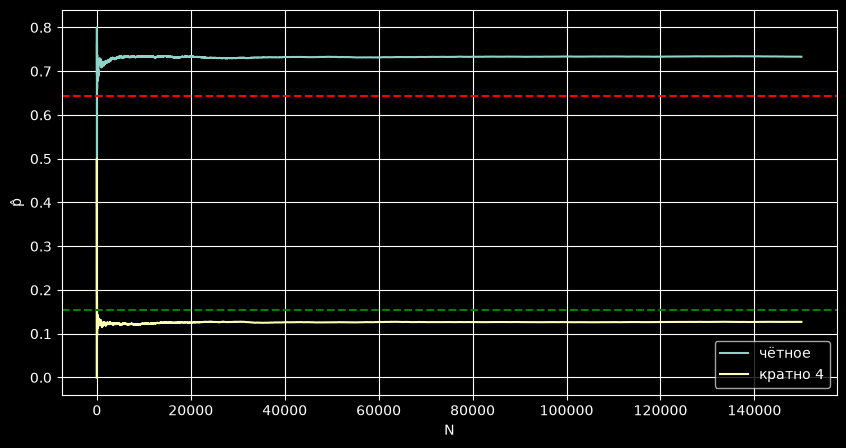

In [1]:
import numpy as np
import matplotlib.pyplot as plt

p, q = 0.7, 0.3

P_even = q*p/(1-p**2) + p*q/(1-q**2)
P_mult4 = q*p**3/(1-p**4) + p*q**3/(1-q**4)
print(f"а) P(чётное)   = {P_even:.16f}")
print(f"б) P(кратно 4) = {P_mult4:.16f}")

def simulate(N, seed=0):
    rng = np.random.default_rng(seed)
    even = np.zeros(N, dtype=bool)
    m4 = np.zeros(N, dtype=bool)
    for i in range(N):
        prev = None
        k = 0
        while True:
            cur = 0 if rng.random() < p else 1   # 0 — герб
            k += 1
            if cur == prev:
                break
            prev = cur
        even[i] = (k % 2 == 0)
        m4[i] = (k % 4 == 0)
    return even, m4

N = 150_000
he, hm = simulate(N, seed=4)
fe = np.cumsum(he)/np.arange(1, N+1)
fm = np.cumsum(hm)/np.arange(1, N+1)

plt.figure(figsize=(10, 5))
plt.plot(fe, label="чётное")
plt.plot(fm, label="кратно 4")
plt.axhline(P_even, color="r", ls="--")
plt.axhline(P_mult4, color="g", ls="--")
plt.xlabel("N"); plt.ylabel("p̂"); plt.legend(); plt.grid(True)
plt.show()